In [9]:
import sys

print(sys.executable)
print(sys.version)

d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline\.venv\Scripts\python.exe
3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]


In [10]:
%pip install -q pandas numpy scikit-learn xgboost mlflow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [11]:
import pandas as pd
import numpy as np
import sklearn
import xgboost
import mlflow
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit
import onnx
import onnxruntime
import skl2onnx
import onnxmltools
import torch

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("MLflow:", mlflow.__version__)

All imports successful!
PyTorch: 2.14.1+cpu
MLflow: 3.17.1


In [13]:

from pathlib import Path
import pandas as pd
import numpy as np

# Correct project root: parent of notebooks/
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

# Create folders in the project root
for folder in [RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Download dataset from Hugging Face
DATA_URL = (
    "https://huggingface.co/datasets/allenborochin/"
    "zomato_delivery_EDA/resolve/main/zomato_cleaned.csv"
)

df_raw = pd.read_csv(DATA_URL)

# Save the original dataset in the correct location
df_raw.to_csv(RAW_DIR / "zomato_cleaned.csv", index=False)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Models directory:", MODELS_DIR)
print("Reports directory:", REPORTS_DIR)
print("Dataset shape:", df_raw.shape)
print("Saved dataset:", (RAW_DIR / "zomato_cleaned.csv").exists())

display(df_raw.head())


Project directory: d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline
Raw data directory: d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline\data\raw
Processed data directory: d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline\data\processed
Models directory: d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline\models
Reports directory: d:\Projects\LEARNINGS\MACHINE LEARNING\Swiftdrop delivery pipeline\reports
Dataset shape: (38964, 22)
Saved dataset: True


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow


Target statistics:


count    38964.000000
mean        26.581511
std          9.339546
min         10.000000
25%         19.000000
50%         26.000000
75%         33.000000
max         54.000000
Name: Time_taken (min), dtype: float64


Missing values:


,missing_count
Delivery_person_Ratings,1055
Delivery_person_Age,1019
Time_Orderd,835
Delivery_person_ID,0
Restaurant_latitude,0
ID,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0



Duplicate rows: 0

Data types:


,dtype
ID,str
Delivery_person_ID,str
Delivery_person_Age,float64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,str
Time_Orderd,str



Target distribution:


<Axes: >

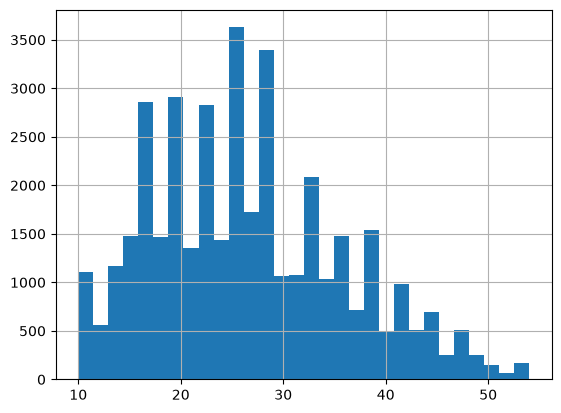

In [14]:
TARGET = "Time_taken (min)"

assert TARGET in df_raw.columns, (
    f"Target not found. Available columns: {df_raw.columns.tolist()}"
)

print("Target statistics:")
display(df_raw[TARGET].describe())

print("\nMissing values:")
display(
    df_raw.isna().sum()
           .sort_values(ascending=False)
           .to_frame("missing_count")
)

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nTarget distribution:")
df_raw[TARGET].hist(bins=30)

In [15]:
  # Normalize whitespace in column names.
df = df_raw.copy()
df.columns = df.columns.str.strip()

TARGET = "Time_taken (min)"

# Validate the target after column normalization.
assert TARGET in df.columns

# This field is derived from the target and must be excluded.
LEAKAGE_COLUMNS = ["delivery_speed"]

# IDs are identifiers, not useful general-purpose numeric predictors.
ID_COLUMNS = ["ID", "Delivery_person_ID"]

excluded = [
    c for c in LEAKAGE_COLUMNS + ID_COLUMNS
    if c in df.columns
]

print("Target:", TARGET)
print("Excluded columns:", excluded)

X = df.drop(columns=[TARGET] + excluded)
y = df[TARGET].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Features:")
print(X.columns.tolist())

Target: Time_taken (min)
Excluded columns: ['delivery_speed', 'ID', 'Delivery_person_ID']
Feature matrix shape: (38964, 18)
Target shape: (38964,)
Features:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'distance_km']


In [16]:
# Inspect numerical feature ranges and categorical values

print("Numerical feature summary:")
display(df.describe(include=[np.number]).T)

print("\nCategorical feature values:")
for col in df.select_dtypes(include=["object"]).columns:
    if col not in excluded:
        print(f"\n{col}:")
        print("Unique values:", df[col].nunique())
        print(df[col].value_counts(dropna=False).head(10))

print("\nPotentially invalid values:")

print(
    "Age outside 18–60:",
    (~df["Delivery_person_Age"].between(18, 60)).sum()
)

print(
    "Ratings outside 1–5:",
    (~df["Delivery_person_Ratings"].between(1, 5)).sum()
)

print(
    "Non-positive distances:",
    (df["distance_km"] <= 0).sum()
)

print(
    "Non-positive targets:",
    (df[TARGET] <= 0).sum()
)

Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,37945.0,29.607089,5.763202,20.000000,25.000000,30.000000,35.000000,39.000000
Delivery_person_Ratings,37909.0,4.631879,0.317006,2.500000,4.500000,4.700000,4.900000,5.000000
Restaurant_latitude,38964.0,18.915583,5.460635,9.957144,12.986047,19.065838,22.751234,30.914057
Restaurant_longitude,38964.0,76.914536,3.498179,72.768726,73.897902,76.618203,78.368855,88.433452
Delivery_location_latitude,38964.0,18.979545,5.462504,9.967144,13.066047,19.124049,22.820072,31.054057
Delivery_location_longitude,38964.0,76.978498,3.498357,72.778726,73.938972,76.663067,78.405467,88.563452
Vehicle_condition,38964.0,0.995534,0.817312,0.000000,0.000000,1.000000,2.000000,2.000000
multiple_deliveries,38964.0,0.749589,0.572172,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken (min),38964.0,26.581511,9.339546,10.000000,19.000000,26.000000,33.000000,54.000000
distance_km,38964.0,9.765092,5.605705,1.465067,4.658009,9.219906,13.681590,20.969489



Categorical feature values:

Order_Date:
Unique values: 44
Order_Date
15-03-2022    1031
03-04-2022    1016
09-03-2022    1013
13-03-2022    1008
05-04-2022    1007
24-03-2022    1005
03-03-2022    1005
07-03-2022    1003
01-03-2022    1001
26-03-2022    1000
Name: count, dtype: int64

Time_Orderd:
Unique values: 176
Time_Orderd
NaN            835
17:55          407
21:55          402
19:50          401
21:15          399
18:35          396
19:55          394
0.833333333    388
21:35          385
21:20          384
Name: count, dtype: int64

Time_Order_picked:
Unique values: 193
Time_Order_picked
21:30          430
18:25          396
18:45          396
18:05          394
21:45          392
21:05          392
22:25          391
17:55          390
22:50          388
0.833333333    387
Name: count, dtype: int64

Weather_conditions:
Unique values: 6
Weather_conditions
Fog           6660
Stormy        6572
Cloudy        6563
Sandstorms    6489
Windy         6436
Sunny         6244
Name: co

C:\Users\dell\AppData\Local\Temp\ipykernel_2936\1788868532.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:


In [17]:
import re
import pandas as pd
import numpy as np

for col in ["Time_Orderd", "Time_Order_picked"]:
    s = df[col].dropna().astype(str).str.strip()

    # Values that are not in standard HH:MM format
    unusual = s[~s.str.fullmatch(r"\d{1,2}:\d{2}")]

    print(f"\n--- {col} ---")
    print("Total non-missing:", len(s))
    print("Standard HH:MM:", len(s) - len(unusual))
    print("Unusual values:", len(unusual))
    print("Most common unusual values:")
    print(unusual.value_counts().head(20))


--- Time_Orderd ---
Total non-missing: 38129
Standard HH:MM: 34619
Unusual values: 3510
Most common unusual values:
Time_Orderd
0.833333333    388
0.791666667    372
1              369
0.875          365
0.958333333    361
0.75           347
0.916666667    342
0.416666667    174
0.5            167
0.458333333    162
0.375          155
0.625           76
0.541666667     70
0.583333333     61
0.708333333     60
0.666666667     41
Name: count, dtype: int64

--- Time_Order_picked ---
Total non-missing: 38964
Standard HH:MM: 34690
Unusual values: 4274
Most common unusual values:
Time_Order_picked
0.833333333    387
24:05:00       370
0.75           366
0.916666667    366
0.875          363
1              362
0.958333333    352
0.791666667    352
24:10:00       233
0.375          180
0.416666667    166
0.5            154
24:15:00       135
0.458333333    127
0.625           79
0.666666667     79
0.583333333     73
0.541666667     69
0.708333333     61
Name: count, dtype: int64


In [18]:
print("Date parsing check:")

parsed_dates = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Unparseable dates:", parsed_dates.isna().sum())
print("Date range:", parsed_dates.min(), "to", parsed_dates.max())

print("\nTarget and distance relationship:")
display(
    df[["distance_km", TARGET]]
    .corr()
    .round(3)
)

print("\nTarget distribution by vehicle type:")
display(
    df.groupby("Type_of_vehicle", observed=True)[TARGET]
      .agg(["count", "mean", "median"])
      .round(2)
)

Date parsing check:
Unparseable dates: 0
Date range: 2022-02-11 00:00:00 to 2022-04-06 00:00:00

Target and distance relationship:


,distance_km,Time_taken (min)
distance_km,1.000,0.322
Time_taken (min),0.322,1.000



Target distribution by vehicle type:


,count,mean,median
Type_of_vehicle,,,
electric_scooter,3096,24.56,24.0
motorcycle,22942,27.85,27.0
scooter,12926,24.81,25.0
